# Development OOF Calibration Assessment

Compares probability calibration diagnostics for all six models using development OOF predictions only. Calibration cannot create discrimination that the model does not possess, so no calibrator is frozen while final model selection remains unresolved.

Canonical FT input: completed GPU run `FT02_20261003T025004Z`, selected in `configs/analysis_registry.yaml`. It uses fixed FT02, inner-AP epoch selection and fresh fitting on inner-training rows; it is not an eight-candidate search. Historical FT evidence remains separate.


## Calibration diagnostics

Loaded 6 headline-model OOF files from development data only.


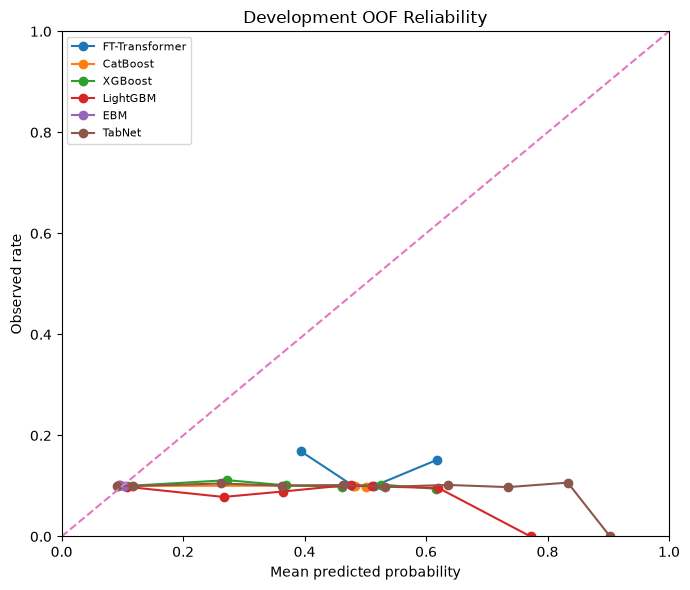

,model,brier_score,ece_10_bins,mean_probability,observed_prevalence
4,EBM,0.090109,0.003337,0.100090,0.1001
2,XGBoost,0.175329,0.227166,0.324106,0.1001
3,LightGBM,0.180215,0.234650,0.331255,0.1001
5,TabNet,0.186177,0.240548,0.337472,0.1001
1,CatBoost,0.210753,0.313725,0.413825,0.1001
0,FT-Transformer,0.247200,0.395671,0.495771,0.1001


{'calibration_model_frozen': False,
 'conclusion': 'Diagnostics are complete, but no calibrator is frozen because no final predictive model is frozen and discrimination is near no-skill.'}

In [1]:
from pathlib import Path
import json, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve, f1_score

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "analysis_registry.yaml").exists():
    for parent in ROOT.parents:
        if (parent / "configs" / "analysis_registry.yaml").exists():
            ROOT = parent
            break
registry = yaml.safe_load((ROOT / "configs" / "analysis_registry.yaml").read_text())
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.models.ebm_experiments import load_formal_ebm_input
from src.models.config import load_model_config

frames = {}
for model, meta in registry["models"].items():
    if model == "EBM":
        ebm_config = load_model_config(ROOT / "configs/models/ebm.yaml", strict_schema=True)
        if meta["oof_path"] != ebm_config["canonical_results"]["oof_predictions"]:
            raise ValueError("Group EBM registry must point to the configured formal OOF input.")
        d, ebm_fold_metrics, ebm_summary = load_formal_ebm_input(ROOT)
    else:
        d = pd.read_csv(ROOT / meta["oof_path"])
    d = d.sort_values("Employee_ID").reset_index(drop=True)
    frames[model] = d
print(f"Loaded {len(frames)} headline-model OOF files from development data only.")
from src.evaluation.calibration import reliability_table, expected_calibration_error
from sklearn.metrics import brier_score_loss
out=ROOT/"results/calibration"; out.mkdir(parents=True,exist_ok=True)
rows=[]
plt.figure(figsize=(7,6))
for model,d in frames.items():
    table=reliability_table(d.y_true,d.y_probability,10); table.insert(0,"model",model); table.to_csv(out/(model.lower().replace("-","_").replace(" ","_")+"_reliability.csv"),index=False)
    valid=table[table["count"]>0]
    plt.plot(valid.mean_probability,valid.observed_rate,marker="o",label=model)
    rows.append({"model":model,"brier_score":brier_score_loss(d.y_true,d.y_probability),"ece_10_bins":expected_calibration_error(d.y_true,d.y_probability,10),"mean_probability":float(d.y_probability.mean()),"observed_prevalence":float(d.y_true.mean())})
summary=pd.DataFrame(rows).sort_values("brier_score"); summary.to_csv(out/"calibration_summary.csv",index=False)
plt.plot([0,1],[0,1],linestyle="--"); plt.xlim(0,1); plt.ylim(0,1); plt.xlabel("Mean predicted probability"); plt.ylabel("Observed rate"); plt.title("Development OOF Reliability"); plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(out/"figure_01_reliability_comparison.png",dpi=160); plt.show()
display(summary.round(6))
decision={"calibration_model_frozen":False,"conclusion":"Diagnostics are complete, but no calibrator is frozen because no final predictive model is frozen and discrimination is near no-skill."}; (out/"calibration_decision.json").write_text(json.dumps(decision,indent=2)); decision

## Conclusion

EBM has the smallest raw Brier score because its probabilities remain close to the low base rate, but that does **not** make it the best discriminator. Calibration and discrimination are reported separately.